# OPTED corpus overview

Loads the dictionary, reports its size, sense counts, collisions, self reference, POS tags, length and the non-learning reference points. Every figure printed here comes from `src/rexdict.py`, the same loader the baselines use, so the numbers agree with `splits/manifest.json` and `results/`.

Cells follow three rules. One purpose per cell, with a caption that states what it reports. Numbers are printed, not typed into prose. Anything that has to be reproducible lives in `src/`, the notebook calls it.

In [1]:
import os
import sys
import glob
import json
import subprocess
import pandas as pd

# the repo is at /kaggle/working/repo on Kaggle, or the project root when run locally
if not os.path.isdir('/kaggle/working/repo/src') and os.path.isdir('/kaggle/working'):
    try:      # needs the notebook internet switch on
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/ByteBandit0608/reverse-dictionary-capstone',
                        '/kaggle/working/repo'])
    except Exception as e:
        print('clone failed:', e)
root = next((p for p in ('/kaggle/working/repo', os.getcwd())
             if os.path.isdir(os.path.join(p, 'src'))), os.getcwd())
sys.path.insert(0, os.path.join(root, 'src'))
if not os.environ.get('REXDICT_CSV'):
    hit = glob.glob(os.path.join(root, 'data', '*.csv')) + \
          glob.glob('/kaggle/input/**/*.csv', recursive=True)
    hit = sorted(set(hit), key=os.path.getsize, reverse=True)
    if hit:
        os.environ['REXDICT_CSV'] = hit[0]

import rexdict as R
print('csv:', R.find_csv())

# the manifest is written by src/make_splits.py, read here rather than recomputed
mpath = os.path.join(root, 'splits', 'manifest.json')
man = pd.read_json(mpath, typ='series') if os.path.exists(mpath) else pd.Series(dtype=object)

csv: /kaggle/input/datasets/dfydata/the-online-plain-text-english-dictionary-opted/OPTED-Dictionary.csv


## 1. Cleaning and size

Cleaning is by pattern rather than by definition length, and drops five things: rows with no usable definition text, rows where the spreadsheet error token appears in the headword or the definition, rows with no headword, cross reference entries, and definitions that contain the word they define. Exact duplicate word and definition pairs go as well.

In [2]:
df, meta = R.load()
for k in ('rows_raw', 'rows_dropped_bad_def', 'rows_dropped_named',
          'rows_named_in_word', 'rows_named_in_definition', 'rows_named_word_exact',
          'rows_dropped_empty_word', 'rows_dropped_crossref', 'rows_dropped_dupes',
          'rows_dropped_self_ref', 'rows', 'n_words', 'n_def_strings', 'rows_per_word'):
    print('%-26s %s' % (k, meta.get(k)))

rows_raw                   176009
rows_dropped_bad_def       215
rows_dropped_named         207
rows_named_in_word         207
rows_named_in_definition   0
rows_named_word_exact      207
rows_dropped_empty_word    4
rows_dropped_crossref      5616
rows_dropped_dupes         232
rows_dropped_self_ref      34039
rows                       135907
n_words                    95286
n_def_strings              130223
rows_per_word              1.426


## 2. Senses per word

words with more than one sense: 20.37%
mean senses per word: 1.426
max senses on one word: 35
most polysemous: {'Run': 35, 'Touch': 33, 'Cast': 32, 'Strike': 29, 'Base': 29, 'Set': 28, 'Pass': 26, 'Line': 25}


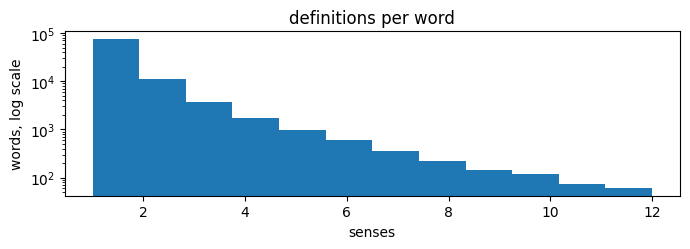

In [3]:
import matplotlib.pyplot as plt

per_word = df.groupby('word').size()
print('words with more than one sense: %.2f%%' % (100.0 * (per_word > 1).mean()))
print('mean senses per word: %.3f' % per_word.mean())
print('max senses on one word: %d' % per_word.max())
print('most polysemous:', per_word.sort_values(ascending=False).head(8).to_dict())
plt.figure(figsize=(7, 2.6))
plt.hist(per_word[per_word <= 12], bins=12)
plt.title('definitions per word')
plt.xlabel('senses')
plt.ylabel('words, log scale')
plt.yscale('log')
plt.tight_layout()
plt.show()

## 3. Definition collisions

Distinct headwords sharing one definition string. This is what bounds strict Recall@1, and it is measured on the query set as well as on the whole file because the two rates differ.

In [4]:
for k in ('pct_shared_def', 'max_tie'):
    print('%-22s %s' % (k, meta.get(k)))
for k in ('ceiling_strict_top1', 'pct_reachable_when_self_removed'):
    print('%-22s %s' % (k, man.get(k)))
short = df['ntok'] < 3
print('tied rows, under 3 tokens:      %.1f%%' % (100.0 * (df.loc[short, 'n_accept'] > 1).mean()))
print('tied rows, 3 tokens or more:    %.1f%%' % (100.0 * (df.loc[~short, 'n_accept'] > 1).mean()))

pct_shared_def         7.86
max_tie                9
ceiling_strict_top1    0.995
pct_reachable_when_self_removed 100.0
tied rows, under 3 tokens:      42.9%
tied rows, 3 tokens or more:    1.2%


## 4. Self reference

Definitions that contain the word they define. The report quotes both the exact token match and the match that also catches inflected forms, the second is what the cleaning applies.

In [5]:
for k in ('pct_rows_self_ref_exact', 'pct_rows_self_ref'):
    print('%-26s %s%%' % (k, meta.get(k)))

pct_rows_self_ref_exact    13.33%
pct_rows_self_ref          19.45%


## 5. Parts of speech

The file carries Webster's own abbreviations in the POS column. Tags are read from the column, headword endings are kept separately as the morphology channel.

In [6]:
from explore_pos import tag_class, classify

print('rows with a tag: %.2f%%' % meta['pct_pos_filled'])
tags = df['pos_raw'].value_counts()
print('distinct tag strings:', len(tags))
print(tags.head(10).to_dict())
print('mapped to classes:', df['pos_raw'].map(tag_class).value_counts().to_dict())
multi = df.groupby('wid')['pos_raw'].apply(lambda s: s.map(tag_class).nunique() > 1)
print('headwords whose senses differ in POS: %.2f%%' % (100.0 * multi.mean()))

rows with a tag: 97.63%
distinct tag strings: 249
{'n.': 70786, 'a.': 26687, 'v. t.': 12505, 'v. i.': 5214, 'adv.': 3913, '': 3217, 'imp. & p. p.': 3189, 'p. pr. & vb. n.': 2877, 'pl. ': 2568, 'n. pl.': 1404}
mapped to classes: {'noun': 72460, 'adj': 26883, 'verb': 18867, 'partic': 6633, 'adv': 4011, 'other': 3356, 'missing': 3217, 'prep': 230, 'interj': 108, 'pron': 82, 'conj': 60}
headwords whose senses differ in POS: 7.09%


## 6. Length and truncation

`max_seq_length` is chosen from this table, not assumed.

token length p50/p90/p95/p99/max: 7 / 22 / 29 / 45 / 148
  max_len= 16  rows truncated:   25449  (18.73%)
  max_len= 32  rows truncated:    4665  (3.43%)
  max_len= 48  rows truncated:     999  (0.74%)
  max_len= 64  rows truncated:     236  (0.17%)
  max_len= 96  rows truncated:      21  (0.02%)
  max_len=128  rows truncated:       2  (0.00%)
  max_len=256  rows truncated:       0  (0.00%)


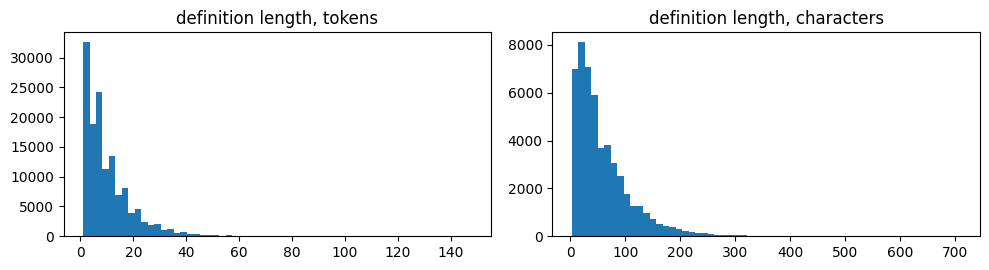

In [7]:
tl = df['ntok']
print('token length p50/p90/p95/p99/max: %d / %d / %d / %d / %d'
      % (tl.quantile(.5), tl.quantile(.9), tl.quantile(.95), tl.quantile(.99), tl.max()))
for L in (16, 32, 48, 64, 96, 128, 256):
    aff = int((tl > L).sum())
    print('  max_len=%3d  rows truncated: %7d  (%.2f%%)' % (L, aff, 100.0 * aff / len(df)))

fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].hist(tl[tl <= 200], bins=60)
ax[0].set_title('definition length, tokens')
ax[1].hist(df['definition'].str.len()[:50000], bins=60)
ax[1].set_title('definition length, characters')
plt.tight_layout()
plt.show()

## 7. Reference points

Two floors a learned model has to clear. Both are near zero on a by-word split, which is expected and is part of why the split is by word.

In [8]:
n_words = meta['n_words']
print('uniform random over the vocabulary: %.2e' % (1.0 / n_words))
if 'count' in df:
    prior = df.groupby('word')['count'].sum().sort_values(ascending=False)
    print('always answer the most frequent word: %.6f  (%r)' % (prior.iloc[0] / df['count'].sum(), prior.index[0]))
    print('always answer from the top 50:        %.6f' % (prior.head(50).sum() / df['count'].sum()))

uniform random over the vocabulary: 1.05e-05
always answer the most frequent word: 0.000157  ('Draught')
always answer from the top 50:        0.004956


## 8. Split

Written out by `src/make_splits.py`. The query set is fixed there and the ids are committed, so every method in `results/` is scored on the same rows.

In [9]:
for k in ('ratios', 'n_words_train', 'n_words_val', 'n_words_test', 'n_queries',
          'min_query_tokens', 'min_senses_per_query_word', 'pct_reachable_when_self_removed',
          'seed'):
    print('%-32s %s' % (k, man.get(k)))

ratios                           80/10/10, split by word
n_words_train                    76229
n_words_val                      9529
n_words_test                     9528
n_queries                        500
min_query_tokens                 3
min_senses_per_query_word        2
pct_reachable_when_self_removed  100.0
seed                             2026
